<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/DOptimalDesign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the course's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('doe'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DoE.git doe')
        os.system('git -C doe sparse-checkout set Python/Data Python/Support')
    path = 'doe/Python/'

Optimal design of the next experiments for pectin extraction (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{X}_b$ | `X_b` | design matrix of the base data (11 experiments) |
| $\mathbf{X}_n$ | `X_n` | design matrix of the new experiments (3) |
| $\mathcal{I}(\hat{\theta},\mathbf{X}_n;\mathbf{X}_b)$ | `FI` | Fisher information with base and new data |
| $\mathrm{Tr}$, $\mathrm{Det}$, $\lambda_{\min}$ | `trace`, `det`, `lam_min` | A-, D- and E-design objectives of the slides |

**Note:** This notebook reproduces the optimal-design example of the slides: the base data cannot identify the quadratic model, and the three new experiments that add the most information are found by trying every combination. The theory is in Sections 5.2.1 and 5.2.4 of *Statistics for Chemical Engineers*. Data: Peng et al., [*Scientific Reports* 10, 3595 (2020)](https://doi.org/10.1038/s41598-020-60339-1).

**The concept.** Information adds up. If base data $\mathbf{X}_b$ exist and we add experiments $\mathbf{X}_n$,

$$\mathcal{I}(\mathbf{X}_n;\mathbf{X}_b)=\begin{bmatrix}\mathbf{X}_b\\ \mathbf{X}_n\end{bmatrix}^T\begin{bmatrix}\mathbf{X}_b\\ \mathbf{X}_n\end{bmatrix}=\mathbf{X}_b^T\mathbf{X}_b+\mathbf{X}_n^T\mathbf{X}_n.$$

Optimal design chooses $\mathbf{X}_n$ to make $\mathcal{I}$ large. Since $\mathcal{I}$ is a matrix, we need a scalar measure, and each has a letter (with $\lambda_i$ the eigenvalues):

* **A-design** (slides): $\max\ \mathrm{Tr}(\mathcal{I})=\sum_i\lambda_i$. (Many texts use $\min\ \mathrm{Tr}(\mathcal{I}^{-1})=\sum_i1/\lambda_i$, the total variance.)
* **D-design:** $\max\ \mathrm{Det}(\mathcal{I})=\prod_i\lambda_i$.
* **E-design:** $\max\ \lambda_{\min}(\mathcal{I})$.

The design space is **discretized**: three points per input (-1, 0, 1) give $3^3=27$ candidates, and choosing 3 of them gives $\binom{27}{3}=2925$ sets, few enough to try all.

In [2]:
from itertools import combinations, product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def features(x):
    """Row(s) of the design matrix for the quadratic model."""
    x1, x2, x3 = np.atleast_2d(x).T
    return np.column_stack([np.ones(len(x1)), x1, x2, x3, x1**2, x2**2, x3**2, x1*x2, x1*x3, x2*x3])

D = np.loadtxt(path + "Data/box_behnken.dat")
x_b = D[:11, :3]                  # base data: the first 11 experiments
X_b = features(x_b)
FI_b = X_b.T @ X_b
print("rank of X_b:", np.linalg.matrix_rank(X_b), "for", X_b.shape[1], "parameters")
print("eigenvalues of the base FI:", np.round(np.abs(np.linalg.eigvalsh(FI_b)), 3))

rank of X_b: 9 for 10 parameters
eigenvalues of the base FI: [ 0.     0.673  1.628  1.689  2.146  4.     5.067  6.325  7.372 22.1  ]


One eigenvalue is zero: the base experiments cannot identify the 10 parameters. Candidates for the
new experiments are the 27 points of a 3-level grid; we evaluate
$\mathcal{I}=\mathbf{X}_b^T\mathbf{X}_b+\mathbf{X}_n^T\mathbf{X}_n$ for every set of 3.

In [3]:
cand = np.array(list(product([-1, 0, 1], repeat=3)), dtype=float)
F = features(cand)
sets = list(combinations(range(len(cand)), 3))

**Evaluate every set.** For each set, build $\mathbf{X}_n$ from the rows of the candidate matrix, add its information to the base information, and compute the three measures from the eigenvalues.

In [4]:
det, lam_min, trace = [], [], []
for s in sets:
    X_n = F[list(s)]
    lam = np.linalg.eigvalsh(FI_b + X_n.T @ X_n)
    det.append(np.prod(lam)); lam_min.append(lam[0]); trace.append(lam.sum())
det, lam_min, trace = map(np.array, (det, lam_min, trace))
print(len(sets), "sets of 3 experiments")

d = np.argmax(det)
X_n = F[list(sets[d])]
print(f"\nD-design: det(I) = {det[d]:.3g}")
print(pd.DataFrame(cand[list(sets[d])], columns=["X_1", "X_2", "X_3"], index=["next 1", "next 2", "next 3"]))

2925 sets of 3 experiments

D-design: det(I) = 1.92e+07
        X_1  X_2  X_3
next 1  1.0 -1.0  1.0
next 2  1.0  1.0 -1.0
next 3  1.0  1.0  1.0


The D- and E-designs select experiments at high temperature ($X_1=1$), the region the base data
does not cover. Several sets tie for the largest trace.

E-design: lambda_min = 1.682
        X_1  X_2  X_3
next 1  1.0 -1.0  1.0
next 2  1.0  1.0  0.0
next 3  1.0  1.0  1.0

largest trace = 81, reached by 56 sets


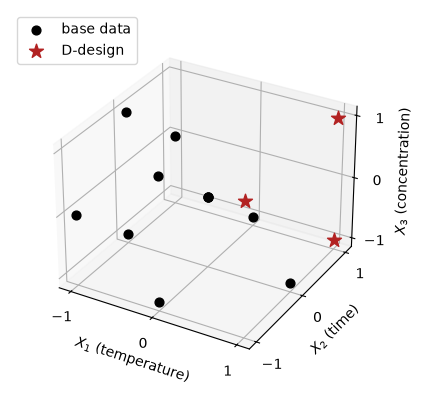

In [5]:
e = np.argmax(lam_min)
print(f"E-design: lambda_min = {lam_min[e]:.3f}")
print(pd.DataFrame(cand[list(sets[e])], columns=["X_1", "X_2", "X_3"], index=["next 1", "next 2", "next 3"]))
n_tie = np.sum(np.isclose(trace, trace.max()))
print(f"\nlargest trace = {trace.max():.0f}, reached by {n_tie} sets")

fig = plt.figure(figsize=(5.5, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*x_b.T, color="black", s=40, label="base data", depthshade=False)
ax.scatter(*cand[list(sets[d])].T, color="firebrick", s=110, marker="*", label="D-design", depthshade=False)
ax.set_xlabel("$X_1$ (temperature)"); ax.set_ylabel("$X_2$ (time)"); ax.set_zlabel("$X_3$ (concentration)")
ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
ax.set_box_aspect(None, zoom=0.88)
ax.legend(loc="upper left"); plt.show()

**Check the math.** The stacked design matrix gives the same information as the sum, and adding the three experiments raises the rank from 9 to 10. The trace ignores how the information is distributed: a set with the largest trace can still leave a small eigenvalue.

In [6]:
X_all = np.vstack([X_b, X_n])
print("stacked = sum:", np.allclose(X_all.T @ X_all, FI_b + X_n.T @ X_n))
print("rank with the new experiments:", np.linalg.matrix_rank(X_all))
tie = np.isclose(trace, trace.max())
print(f"lambda_min among the sets of largest trace: from {lam_min[tie].min():.3f} to {lam_min[tie].max():.3f} (best of all sets {lam_min.max():.3f})")

stacked = sum: True
rank with the new experiments: 10
lambda_min among the sets of largest trace: from 0.042 to 1.624 (best of all sets 1.682)


**Note:** The base design is singular (zero determinant), so its estimates are not unique. Three well-chosen experiments make every eigenvalue positive; how "informative" a set is depends on the criterion (determinant, smallest eigenvalue or trace).